# DAT 301 Project 2 - Human Behavior in Rock Paper Scissors 

## Project Summary

This project analyzes human behavior in rock-paper-scissors games. Using conditional probabilities, I will examine how often each choice occurs depending on the player's and opponent's previous choices and results. I will also examine sequential behavior to see how previous experiences are related to future choices and whether these patterns can be used to build a simple model.

This dataset is from a Rock-Paper-Scissors experiment conducted at Zhejiang University between 2010 and 2014. A total of 360 students participated in the experiment. The dataset contains their choices and results from repeated Rock-Paper-Scissors games, which can be used to explore patterns in how people make decisions during the game.  https://rdrr.io/cran/stratEst/man/WXZ2014.html


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("RPS.csv")
df.head()

,id,game,period,choice,other.choice,result
0,1,1,1,s,s,tie
1,1,1,2,s,r,lose
2,1,1,3,s,p,win
3,1,1,4,s,p,win
4,1,1,5,s,p,win


## 1. Data Overview

- id : participant ID
- game : game identifier
- period : round number, each person plays 300 rounds
- choice participant's choice (r, p, s)
- other.choice : opponent's choice
- result : participant's outcome (win, lose, tie)


In [45]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nNumber of rounds:", max(df["period"]))

print("\nChoices:", df["choice"].unique())
print("Opponent choices:", df["other.choice"].unique())
print("Result:", df["result"].unique())

df.describe()

Shape: (21600, 6)

Data types:
id               int64
game             int64
period           int64
choice          object
other.choice    object
result          object
dtype: object

Missing values:
id              0
game            0
period          0
choice          0
other.choice    0
result          0
dtype: int64

Number of rounds: 300

Choices: ['s' 'r' 'p']
Opponent choices: ['s' 'r' 'p']
Result: ['tie' 'lose' 'win']


,id,game,period
count,21600.000000,21600.0,21600.000000
mean,36.500000,1.0,150.500000
std,20.783086,0.0,86.604064
min,1.000000,1.0,1.000000
25%,18.750000,1.0,75.750000
50%,36.500000,1.0,150.500000
75%,54.250000,1.0,225.250000
max,72.000000,1.0,300.000000


## 2. Data Wrangling and Feature Engineering



In [46]:
df = df.sort_values(["id", "period"]).reset_index(drop=True)

# Remove game because it has only one value
df = df.drop(columns=["game"])

# Columns representing previous round
df["prev_choice"] = df.groupby("id")["choice"].shift(1)
df["prev_result"] = df.groupby("id")["result"].shift(1)
df["prev_other_choice"] = df.groupby("id")["other.choice"].shift(1)

# First round
first_behavior_df = (df[df["prev_choice"].isna()].copy().reset_index(drop=True))

# Later rounds
behavior_df = (df[df["prev_choice"].notna()].copy().reset_index(drop=True))



## 3. Exploratory Data Analysis




### Behavior of first rounds 

In [47]:
first_behavior_df.head()

,id,period,choice,other.choice,result,prev_choice,prev_result,prev_other_choice
0,1,1,s,s,tie,NaN,NaN,NaN
1,2,1,p,p,tie,NaN,NaN,NaN
2,3,1,r,r,tie,NaN,NaN,NaN
3,4,1,r,p,lose,NaN,NaN,NaN
4,5,1,s,s,tie,NaN,NaN,NaN


In [48]:
pd.DataFrame({
    "Percentage": first_behavior_df["choice"].value_counts(normalize=True) * 100}).round(2)

,Percentage
choice,
r,58.33
p,26.39
s,15.28


In the first round, rock was the most common choice.

### Behavior of Subsequent Rounds

In [49]:
pd.DataFrame({
    "Percentage": behavior_df["choice"].value_counts(normalize=True)*100}).round(2)


,Percentage
choice,
r,35.58
p,32.25
s,32.17


In the subsequent rounds, the three choices had approximately equal probabilities, with rock being slightly higher than the other two.

In [50]:
pd.DataFrame({
    "Percentage": behavior_df["result"].value_counts(normalize=True)*100}).round(2)


,Percentage
result,
tie,33.56
lose,33.22
win,33.22


The result of subsequent rounds also had equal probabilities too.

## 1. Behavior Transition 

In [51]:
transition = (
    pd.crosstab(
        [behavior_df["prev_result"], behavior_df["prev_choice"]],
        behavior_df["choice"],
        normalize="index") * 100).round(2)

transition

choice                       p      r      s
prev_result prev_choice                     
lose        p            50.92  27.01  22.07
            r            26.04  53.42  20.53
            s            20.68  25.85  53.47
tie         p            41.54  36.18  22.28
            r            22.65  45.45  31.89
            s            32.57  25.09  42.34
win         p            33.94  30.38  35.68
            r            37.56  37.84  24.61
            s            27.61  36.26  36.13

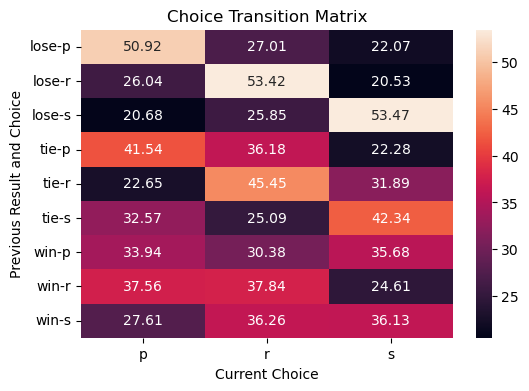

In [52]:
plt.figure(figsize=(6, 4))
sns.heatmap(transition, annot=True, fmt=".2f")
plt.xlabel("Current Choice")
plt.ylabel("Previous Result and Choice")
plt.title("Choice Transition Matrix")
plt.show()

A clear pattern we can see from this matrix is that after a loss, there was highest probability of staying rather changing option regardless of rock, paper, or scissors.

## 2. Behavior After Losing





In [53]:
behavior_df["behavior"] = np.where(behavior_df["choice"] == behavior_df["prev_choice"], "Stay", "Switch")

behavior_by_prev = (
    pd.crosstab(
        behavior_df["prev_result"], behavior_df["behavior"], normalize= "index") * 100).round(2)

behavior_by_prev

behavior,Stay,Switch
prev_result,,
lose,52.67,47.33
tie,43.25,56.75
win,35.97,64.03


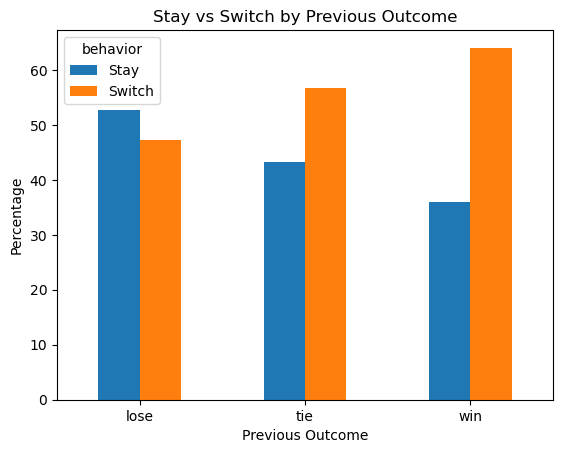

In [54]:
behavior_by_prev.plot(kind="bar")
plt.title("Stay vs Switch by Previous Outcome")
plt.xlabel("Previous Outcome")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

A pattern we can see here is that stay behavior tends to decrease gradually from a loss to a win, while switch behavior tends to increase gradually from a loss to a win.

## 3. Behavior After Winning

In [55]:
win_transition = pd.crosstab(
    behavior_df.loc[behavior_df["prev_result"] == "win", "prev_choice"],
     behavior_df.loc[behavior_df["prev_result"] == "win", "choice"],
     normalize="index") * 100

win_transition

choice,p,r,s
prev_choice,,,
p,33.940867,30.376671,35.682463
r,37.555110,37.835671,24.609218
s,27.609890,36.263736,36.126374


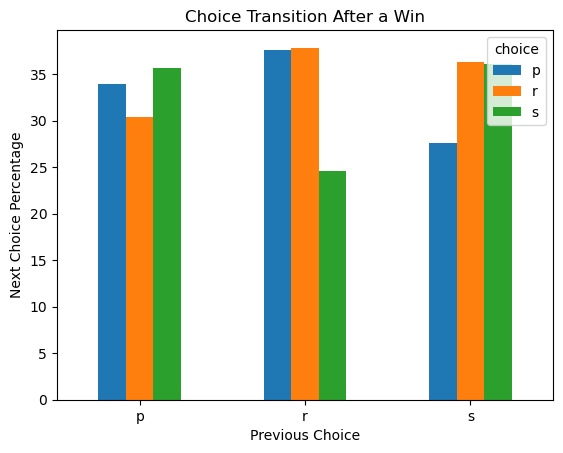

In [56]:
win_transition.plot(kind="bar")

plt.title("Choice Transition After a Win")
plt.xlabel("Previous Choice")
plt.ylabel("Next Choice Percentage")
plt.xticks(rotation=0)
plt.show()


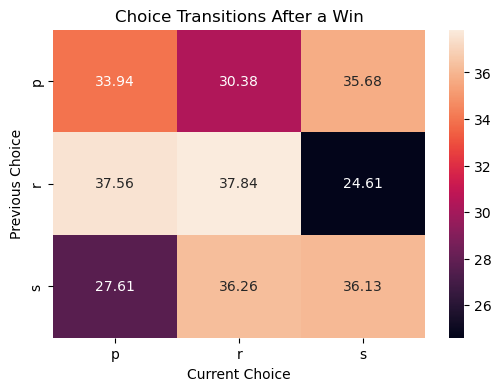

In [57]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    win_transition,
    annot=True,
    fmt=".2f"
)

plt.xlabel("Current Choice")
plt.ylabel("Previous Choice")
plt.title("Choice Transitions After a Win")

plt.show()

The next choice distribution was different depending on the previous choice. After rock, they chose rock and paper at similar rates, while scissors was chosen much less. After paper, scissors was slightly the most common choice. After scissors, rock and scissors were chosen at similar rates, while paper was less common. There was no single transition pattern across all three choices.

## 4. Behavior After Tieing

I next examine what participants choose after a tied round.


In [58]:
tie_transition = (pd.crosstab(
    behavior_df.loc[behavior_df["prev_result"] == "tie", "prev_choice"],
    behavior_df.loc[behavior_df["prev_result"] == "tie", "choice"],
    normalize="index") * 100).round(2)

tie_transition

choice,p,r,s
prev_choice,,,
p,41.54,36.18,22.28
r,22.65,45.45,31.89
s,32.57,25.09,42.34


<Figure size 600x400 with 0 Axes>

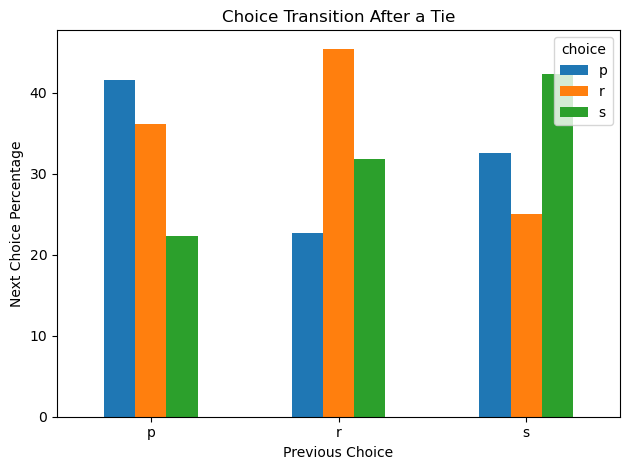

In [59]:
plt.figure(figsize=(6, 4))
tie_transition.plot(kind="bar")

plt.title("Choice Transition After a Tie")
plt.xlabel("Previous Choice")
plt.ylabel("Next Choice Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

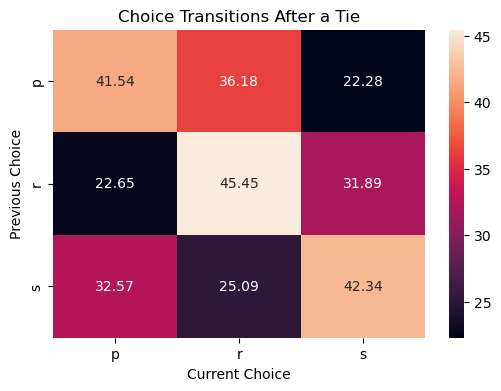

In [60]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    tie_transition,
    annot=True,
    fmt=".2f"
)

plt.xlabel("Current Choice")
plt.ylabel("Previous Choice")
plt.title("Choice Transitions After a Tie")

plt.show()

After a tie, repeating the same choice is the most common transition. 


## 5. Response to the Opponent's Previous Choice

This time let's see if there's effect of opponent's previous choice 

In [61]:
opponent_effect = (pd.crosstab(
    behavior_df["prev_other_choice"],
    behavior_df["choice"],
    normalize="index") * 100).round(2)

opponent_effect

choice,p,r,s
prev_other_choice,,,
p,31.65,42.33,26.01
r,25.65,34.22,40.13
s,40.17,30.30,29.53


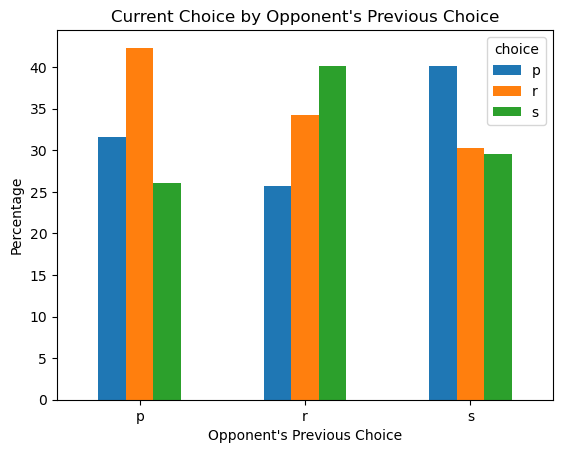

In [62]:
opponent_effect.plot(kind="bar")
plt.title("Current Choice by Opponent's Previous Choice")
plt.xlabel("Opponent's Previous Choice")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

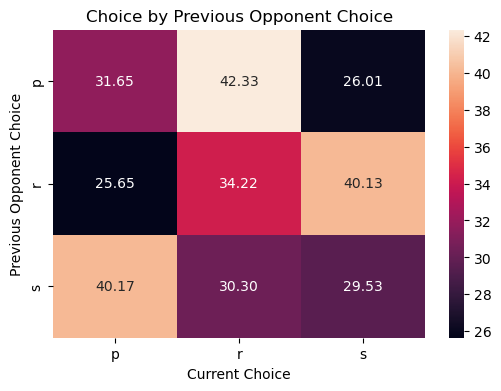

In [63]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    opponent_effect,
    annot=True,
    fmt=".2f"
)

plt.xlabel("Current Choice")
plt.ylabel("Previous Opponent Choice")
plt.title("Choice by Previous Opponent Choice")

plt.show()

- Previous opponent Paper → Current Rock 
- Previous opponent Rock → Current Scissors 
- Previous opponent Scissors → Current Paper

Interestingly, the player tended to choose the option that would have lost to the opponent's previous choice. 
This suggests that players' next choices may be related to the opponent's previous move.

# 9. Prediction Strategy

Finally, I will test whether the behavioral patterns can be used to predict future choices.

- Training data: rounds 1–200
- Test data: rounds 201–300


In [64]:
train = behavior_df[behavior_df["period"] <= 200].copy()
test = behavior_df[behavior_df["period"] > 200].copy()

### Constructing the Strategy

Based on the patterns found in the training data, I manually created the prediction rules

* Previous result = Lose -> Stay
Predict the same choice as the player's previous choice.

* Previous result = Tie -> Stay
Predict the same choice as the player's previous choice.

* Previous result = Win -> Change based on the opponent's previous choice

  * Opponent chose Paper -> predict Rock

  * Opponent chose Rock -> predict Scissors

  * Opponent chose Scissors -> predict Paper




In [65]:
def predict_choice(row):
    if row["prev_result"] == "lose":
        return row["prev_choice"]

    elif row["prev_result"] == "tie":
        return row["prev_choice"]

    else: 
        if row["prev_other_choice"] == "p":
            return "r"
        elif row["prev_other_choice"] == "r":
            return "s"
        else:
            return "p"


test["model_choice"] = test.apply(predict_choice, axis=1)

In [66]:
def mod(row):
    model = row["model_choice"]
    human = row["choice"]

    if model == human:
        return "Tie"

    if ((model == "r" and human == "s") or
        (model == "p" and human == "r") or
        (model == "s" and human == "p")):

        return "Win"
        
    else:
        return "Lose"


test["model_result"] = test.apply(mod, axis=1)
result_rate = test["model_result"].value_counts(normalize=True) * 100

print(result_rate)

model_result
Tie     46.305556
Win     30.750000
Lose    22.944444
Name: proportion, dtype: float64


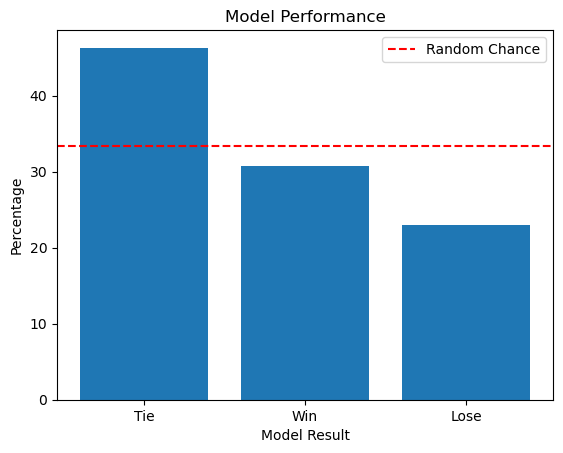

In [67]:
plt.bar(
    result_rate.index,
    result_rate.values
)

plt.axhline(
    100/3,
    ls="--",
    color="red",
    label="Random Chance"
)

plt.xlabel("Model Result")
plt.ylabel("Percentage")
plt.title("Model Performance")
plt.legend()
plt.show()


# Limitations
A major discrepancy in social behavior is that people at the macroscopic level may act like one group, but at the microscopic level, individual behaviors can be very different.
I will take individual stay behavior as an example to see such discrepancy. 

In [68]:
individual_stay = (
    behavior_df[behavior_df["prev_result"] == "lose"]
    .groupby("id")["behavior"]
    .apply(lambda x: (x == "Stay").mean() * 100)
    .reset_index(name="loss_stay_rate")
)

individual_stay["loss_stay_rate"] = (
    individual_stay["loss_stay_rate"].round(2)
)

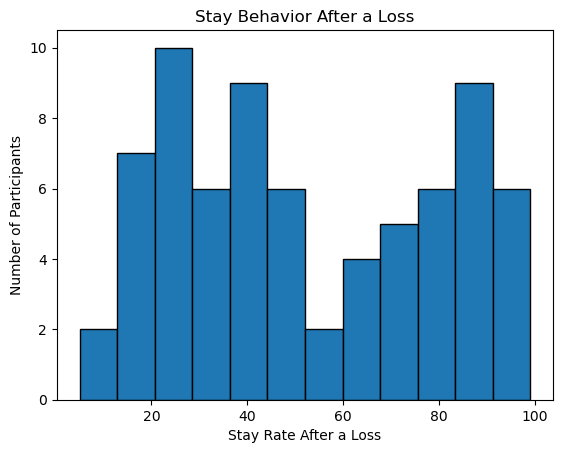

In [69]:
plt.hist(
    individual_stay["loss_stay_rate"],
    bins=12,
    edgecolor="black"
)

plt.xlabel("Stay Rate After a Loss")
plt.ylabel("Number of Participants")
plt.title("Stay Behavior After a Loss")
plt.show()

Like I guessed, the individuals in the group did not all follow the same behavioral pattern. Although the overall stay rate after a loss was around 53%, there was a large variation between individuals. This shows that a pattern observed at the group level does not necessarily represent the individual behavior.

In [70]:
individual_behavior = (behavior_df.groupby(["id", "prev_result"])["behavior"]
    .apply(lambda x: (x == "Stay").mean() * 100)
    .unstack()
    .reset_index())

individual_behavior.head()

prev_result,id,lose,tie,win
0,1,81.553398,47.777778,26.415094
1,2,75.454545,77.551020,73.626374
2,3,54.000000,39.772727,28.828829
3,4,51.020408,57.142857,28.125000
4,5,29.203540,23.711340,13.483146


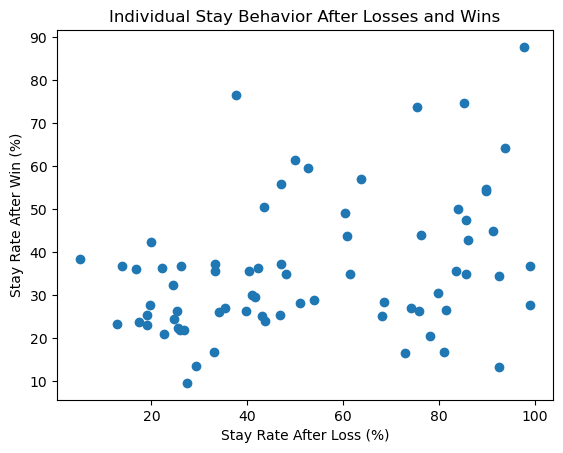

In [71]:
plt.scatter(individual_behavior["lose"],individual_behavior["win"])

plt.xlabel("Stay Rate After Loss (%)")
plt.ylabel("Stay Rate After Win (%)")
plt.title("Individual Stay Behavior After Losses and Wins")
plt.show()

There seems to be a slight positive relationship between stay rates after losses and wins. However, individuals were widely spread out, showing that participants did not follow one consistent behavioral pattern.

## Further Statistical Analysis

In [72]:
# First step transition
P = pd.crosstab(behavior_df["choice"], behavior_df["prev_choice"], normalize="columns")
P

prev_choice,p,r,s
choice,,,
p,0.417878,0.285919,0.26711
r,0.312365,0.455411,0.28896
s,0.269757,0.258670,0.44393


In [73]:
# Second step transition
P @ P

prev_choice,p,r,s
choice,,,
p,0.335988,0.318784,0.312817
r,0.350734,0.371455,0.343309
s,0.313278,0.309761,0.343874


In [74]:
behavior_df["second_step"] = behavior_df["choice"].shift(-2)
pd.crosstab(behavior_df["choice"], behavior_df["second_step"], normalize="index")

second_step,p,r,s
choice,,,
p,0.354128,0.322720,0.323152
r,0.333725,0.393132,0.273143
s,0.278371,0.347820,0.373809


# Markov-chain 

In [86]:
theory = np.linalg.matrix_power(P,5)
pd.DataFrame(theory,
index = ["p","r","s"],
columns = ["p","r","s"])

,p,r,s
p,0.322452,0.322419,0.322357
r,0.355715,0.355784,0.355638
s,0.321833,0.321796,0.322005


In [82]:
behavior_df["fifth_step"] = behavior_df["choice"].shift(-5)
actual = pd.crosstab(behavior_df["choice"] , behavior_df["fifth_step"], normalize="index")
actual


fifth_step,p,r,s
choice,,,
p,0.341449,0.346060,0.312491
r,0.330939,0.371033,0.298028
s,0.294296,0.348881,0.356823


In [77]:
(theory - actual) * 100

fifth_step,p,r,s
choice,,,
p,-1.899713,-2.364031,0.986644
r,2.477600,-1.524866,5.761003
s,2.753674,-2.708458,-3.481852


MAE (Mean Absolute Error) - how far your predictions are from the actual values on average, ignoring whether the error is positive or negative.

In [78]:
MAE = np.mean(np.abs(actual-theory))
MAE*100

np.float64(2.6619823587614952)

Eigenvalues represent what happens to mode over time and 
eigenvectors represent the direction of system 

In [79]:
eigenvalues, eigenvectors = np.linalg.eig(P)
eigenvalues, eigenvectors

(array([1.        , 0.13621038, 0.1810085 ]),
 array([[-0.55780206, -0.77847053, -0.3103014 ],
        [-0.61542288,  0.60251379, -0.49890189],
        [-0.55687659,  0.17595674,  0.80920328]]))

Stationary probability distribution
* pick the eigenvector whose eigenvalue is \(1\) because we're looking for a probability distribution that doesn't change after applying the transition matrix.
* pi is the long-run equilibrium probabilities

In [80]:
v = np.array([0.5578, 0.6154, 0.5569])
pi = v / np.sum(v)

pi

array([0.32240911, 0.35570198, 0.32188891])

If this transition process continues for a long time, the distribution approaches roughly 32.2% Rock, 35.6% Paper, and 32.2% Scissors

In [ ]:
# Actual 299th transition from the data
last = np.linalg.matrix_power(P, 299)
pd.DataFrame(last,
index = ["p","r","s"],
columns = ["p","r","s"])

,p,r,s
p,0.322410,0.322410,0.322410
r,0.355715,0.355715,0.355715
s,0.321875,0.321875,0.321875


Regardless of whether you started at Rock, Paper, or Scissors, after 299 transitions the probabilities should essentially be the same

In [96]:
# Theoretical 299th transiton
behavior_df["299th_step"] = behavior_df["choice"].shift(-299)
actual = pd.crosstab(behavior_df["choice"] , behavior_df["299th_step"], normalize="index")
actual


299th_step,p,r,s
choice,,,
p,0.315275,0.359959,0.324766
r,0.326531,0.351577,0.321892
s,0.327286,0.356255,0.316459


In [100]:
np.mean(np.abs(actual.to_numpy() - theory))*100

np.float64(1.7746722386531157)

The Markov model's 299-step transition probabilities differ from the observed probabilities by about 1.8 percentage points on average.

# 10. Conclusion

The exploratory analysis shows several sequential patterns in repeated Rock Paper Scissors behavior. Participants show different Stay and Switch behaviors depending on the previous outcome, their choices are associated with the opponent's previous move, and tied rounds show asymmetric transition behavior.

These results suggest that repeated Rock-Paper-Scissors behavior contains sequential structure that can provide predictive information. However, the analysis is observational and the identified patterns should not be interpreted as evidence of specific psychological mechanisms or causal effects.

